# Treinamento do Modelo SARIMAX

Previsão do estoque a ser mantido para cada planta vendida na floricultura.

## Fluxo do pipeline
1. **Carregamento** dos dados `contas_a_receber_discretizado.csv`
2. **Preparação** de séries mensais por produto
3. **Engenharia de features** exógenas (mercado + produto)
4. **Importância de variáveis** via Random Forest → ponderação dos regressores
5. **Seleção automática de ordem** SARIMAX por AIC
6. **Treinamento** e **avaliação** (MAE, RMSE, MAPE, R²)
7. **Gravação** de gráficos e métricas em `results/`

In [1]:
import sys
import os

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from src.models.sarimax_model import (
    load_data,
    prepare_monthly_data,
    build_exogenous_features,
    compute_feature_importance,
    weight_features,
    check_stationarity,
    suggest_d,
    select_sarimax_order,
    fit_sarimax,
    evaluate_model,
    plot_forecast,
    plot_residuals,
    run_product_pipeline,
    run_full_pipeline,
    get_top_products,
    PLOTS_DIR,
    METRICS_DIR,
)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100
print('Imports OK')

Imports OK


## 1. Carregamento dos dados

In [2]:
DATA_PATH = os.path.join(project_root, 'data', 'processed', 'contas_a_receber_discretizado.csv')

df = load_data(DATA_PATH)
print(f'Registros carregados: {len(df):,}')
print(f'Período: {df["emissao"].min().date()} a {df["emissao"].max().date()}')
print(f'Produtos únicos: {df["produto_cod"].nunique():,}')
df.head()

Registros carregados: 324,825
Período: 2024-01-02 a 2026-02-28
Produtos únicos: 5,166


,doc_numero,pagamento,emissao,cliente_cod,empresa,vendedor,produto_cod,qtdade,vl_unit,vl_total,vl_desconto,tot_liq,total_liquido_doc
0,47653,5,2024-04-01,1.0,3,31,00020227,3.0,18.0,54.0,3.0,51.0,51
1,47654,5,2024-04-01,1.0,3,33,2155,1.0,79.9,79.9,0.0,79.9,"123,90"
2,47654,5,2024-04-01,1.0,3,33,00200512,20.0,1.0,20.0,0.0,20.0,"123,90"
3,47654,5,2024-04-01,1.0,3,33,224,2.0,12.0,24.0,0.0,24.0,"123,90"
4,47655,4,2024-04-01,1.0,3,31,256,1.0,48.0,48.0,0.0,48.0,48


## 2. Seleção dos produtos a modelar

Usamos os **10 produtos mais vendidos** (por quantidade), que representam as plantas com maior giro de estoque.

In [3]:
TOP_N = 10
top_products = get_top_products(df, TOP_N)

vendas_top = (
    df.groupby('produto_cod')['qtdade'].sum()
    .sort_values(ascending=False)
    .head(TOP_N)
    .reset_index()
)
vendas_top.columns = ['produto_cod', 'qtd_total']
vendas_top['participacao_%'] = (vendas_top['qtd_total'] / df['qtdade'].sum() * 100).round(2)
print('Top produtos selecionados para modelagem:')
display(vendas_top)

Top produtos selecionados para modelagem:


,produto_cod,qtd_total,participacao_%
0,147,911466.00,25.43
1,3,397781.50,11.10
2,00013475,162794.45,4.54
3,710,63241.10,1.76
4,00030197,61172.80,1.71
5,2391,52772.00,1.47
6,650,48461.00,1.35
7,167,46389.00,1.29
8,64,40686.00,1.14
9,143,38253.00,1.07


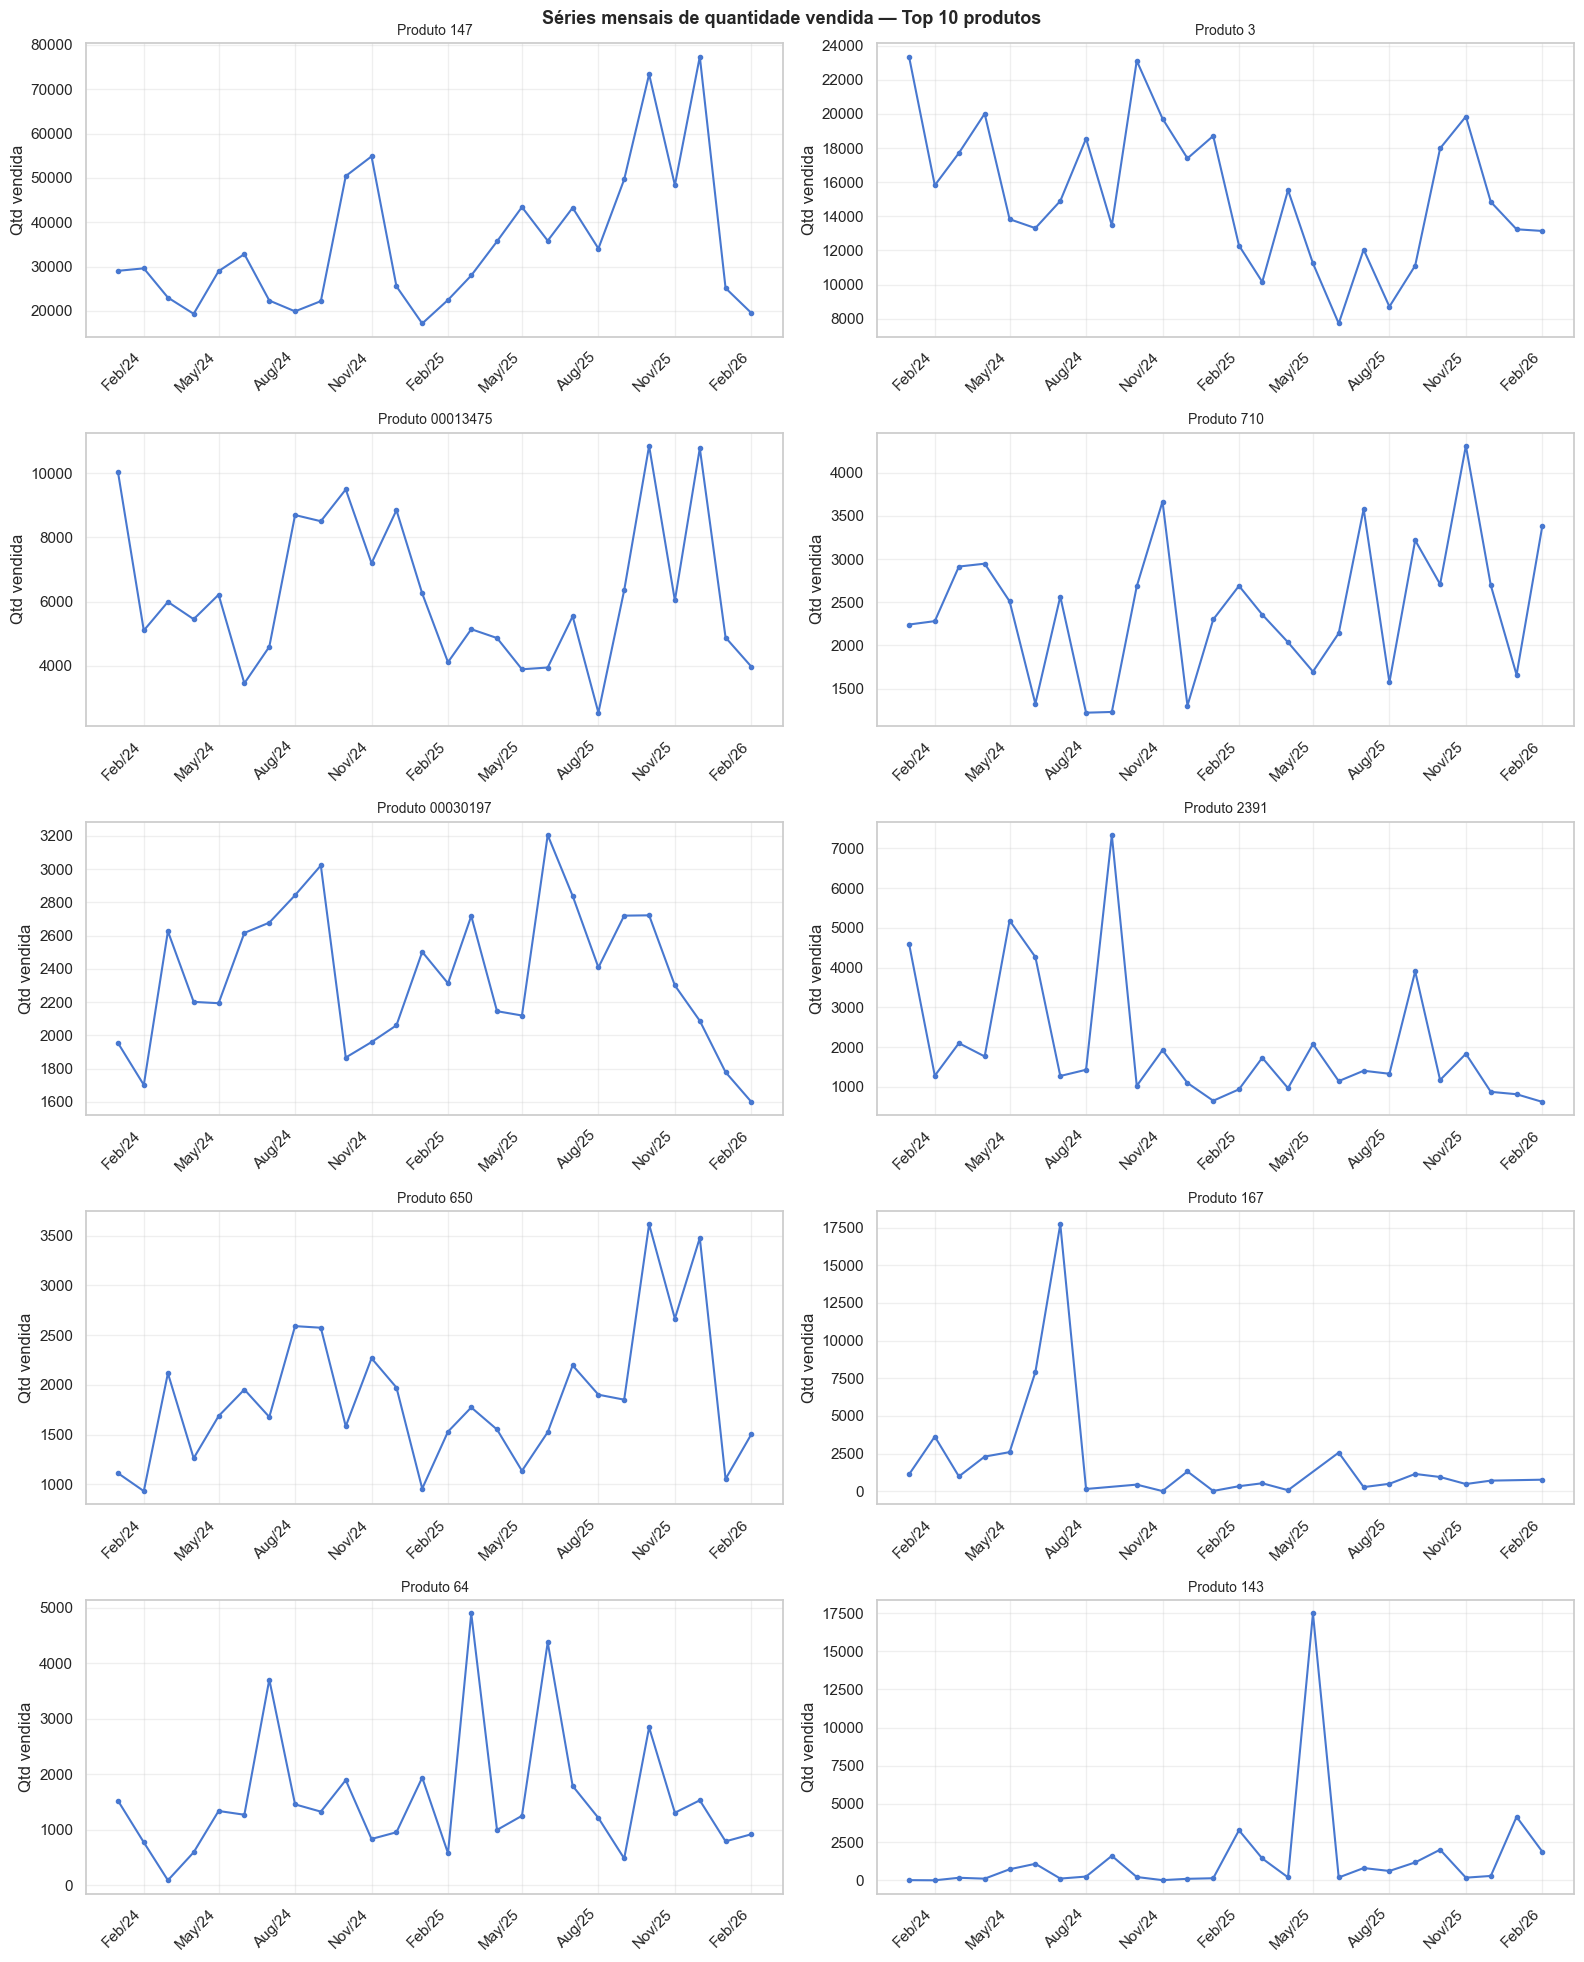

Salvo: c:\Users\felip\OneDrive\Documentos\Estudos\TCC\TCC---Inventory-Forecasting\results\plots\series_temporais_top10.png


In [4]:
fig, axes = plt.subplots(5, 2, figsize=(16, 20))
axes = axes.flatten()

for i, prod in enumerate(top_products):
    ts = prepare_monthly_data(df, prod)
    ax = axes[i]
    ax.plot(ts.index, ts.values, marker='o', markersize=3, linewidth=1.5)
    ax.set_title(f'Produto {prod}', fontsize=10)
    ax.set_ylabel('Qtd vendida')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b/%y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    ax.grid(True, alpha=0.3)

plt.suptitle('Séries mensais de quantidade vendida — Top 10 produtos', fontsize=13, fontweight='bold')
plt.tight_layout()
save_path = PLOTS_DIR / 'series_temporais_top10.png'
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Salvo: {save_path}')

## 3. Análise exploratória das features exógenas

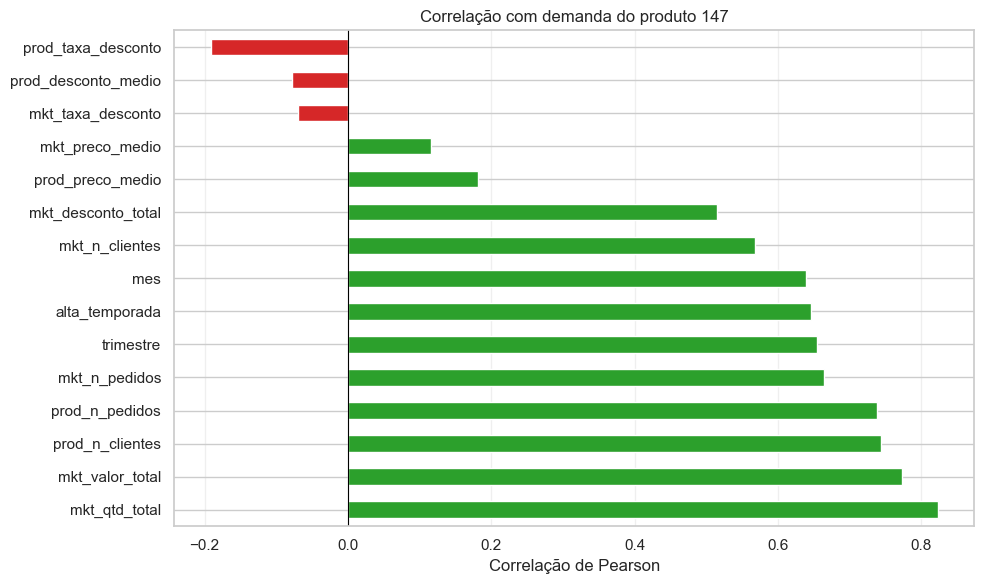

In [5]:
prod_ref = top_products[0]
ts_ref = prepare_monthly_data(df, prod_ref)
exog_ref = build_exogenous_features(df, prod_ref)
exog_ref = exog_ref.reindex(ts_ref.index).ffill().fillna(0)

merged = exog_ref.copy()
merged['target_qtd'] = ts_ref
corr = merged.corr()['target_qtd'].drop('target_qtd').sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#2ca02c' if v > 0 else '#d62728' for v in corr.values]
corr.plot(kind='barh', ax=ax, color=colors, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title(f'Correlação com demanda do produto {prod_ref}', fontsize=12)
ax.set_xlabel('Correlação de Pearson')
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / f'correlacao_produto_{prod_ref}.png', dpi=150, bbox_inches='tight')
plt.show()

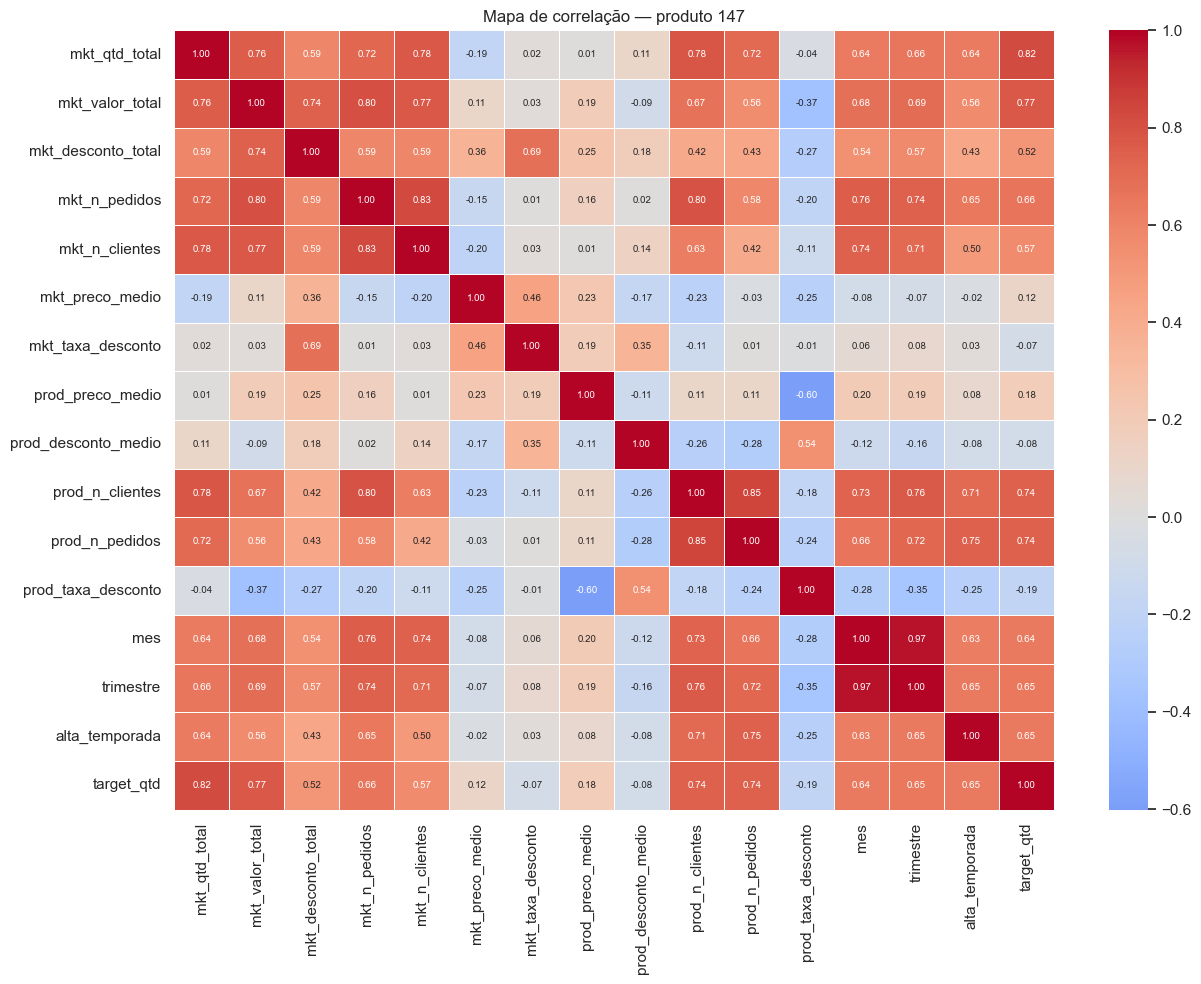

In [6]:
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    merged.corr(), annot=True, fmt='.2f', cmap='coolwarm',
    center=0, ax=ax, annot_kws={'size': 7}, linewidths=0.5
)
ax.set_title(f'Mapa de correlação — produto {prod_ref}', fontsize=12)
plt.tight_layout()
plt.savefig(PLOTS_DIR / f'heatmap_correlacao_{prod_ref}.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Teste de Estacionariedade

In [7]:
print('=' * 60)
print('Teste de Estacionariedade — Top produtos')
print('=' * 60)

stat_rows = []
for prod in top_products:
    ts = prepare_monthly_data(df, prod)
    stat = check_stationarity(ts)
    d = suggest_d(ts)
    stat_rows.append({
        'produto': prod,
        'adf_p': round(stat['adf_p_value'], 4),
        'adf_estac': stat['adf_stationary'],
        'kpss_p': round(stat['kpss_p_value'], 4),
        'kpss_estac': stat['kpss_stationary'],
        'd_sugerido': d,
        'n_meses': len(ts),
    })

stat_df = pd.DataFrame(stat_rows)
display(stat_df)

Teste de Estacionariedade — Top produtos


,produto,adf_p,adf_estac,kpss_p,kpss_estac,d_sugerido,n_meses
0,147,0.0333,True,0.0791,True,0,26
1,3,0.1461,False,0.0882,True,1,26
2,00013475,0.0012,True,0.1000,True,0,26
3,710,0.0000,True,0.1000,True,0,26
4,00030197,0.0293,True,0.1000,True,0,26
5,2391,0.0000,True,0.0464,False,0,26
6,650,0.0023,True,0.1000,True,0,26
7,167,0.9991,False,0.1000,True,1,23
8,64,0.0000,True,0.1000,True,0,26
9,143,0.0000,True,0.1000,True,0,26


## 5. Importância das variáveis

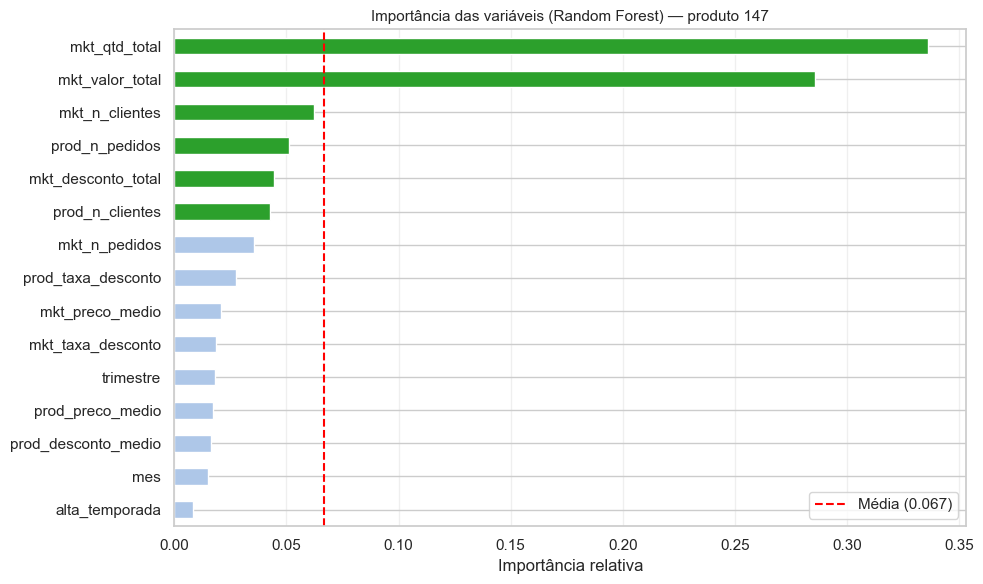


Top 5 variáveis (maior peso no modelo):
mkt_qtd_total         0.336363
mkt_valor_total       0.285628
mkt_n_clientes        0.062466
prod_n_pedidos        0.050941
mkt_desconto_total    0.044659

Bottom 5 variáveis (menor peso, mas incluídas):
trimestre              0.018033
prod_preco_medio       0.017195
prod_desconto_medio    0.016210
mes                    0.015165
alta_temporada         0.008122


In [8]:
TEST_MONTHS = 4

ts_train = ts_ref.iloc[:-TEST_MONTHS]
exog_train = exog_ref.iloc[:-TEST_MONTHS]

importances = compute_feature_importance(exog_train, ts_train)

fig, ax = plt.subplots(figsize=(10, 6))
imp_sorted = importances.sort_values()
colors = ['#2ca02c' if v >= imp_sorted.quantile(0.6) else '#aec7e8' for v in imp_sorted.values]
imp_sorted.plot(kind='barh', ax=ax, color=colors, edgecolor='white')
ax.set_title(f'Importância das variáveis (Random Forest) — produto {prod_ref}', fontsize=11)
ax.set_xlabel('Importância relativa')
ax.grid(True, axis='x', alpha=0.3)
ax.axvline(importances.mean(), color='red', linestyle='--', label=f'Média ({importances.mean():.3f})')
ax.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / f'importancia_vars_{prod_ref}.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nTop 5 variáveis (maior peso no modelo):')
print(importances.sort_values(ascending=False).head(5).to_string())
print('\nBottom 5 variáveis (menor peso, mas incluídas):')
print(importances.sort_values(ascending=False).tail(5).to_string())

In [9]:
exog_train_w = weight_features(exog_train, importances)
print('Features originais (primeiros 3 meses):')
display(exog_train.head(3).round(2))
print('\nFeatures ponderadas por importância:')
display(exog_train_w.head(3).round(2))

Features originais (primeiros 3 meses):


,mkt_qtd_total,mkt_valor_total,mkt_desconto_total,mkt_n_pedidos,mkt_n_clientes,mkt_preco_medio,mkt_taxa_desconto,prod_preco_medio,prod_desconto_medio,prod_n_clientes,prod_n_pedidos,prod_taxa_desconto,mes,trimestre,alta_temporada
emissao,,,,,,,,,,,,,,,
2024-01-01,154862.13,1528187.60,27800.67,4097,400,39.79,0.02,3.34,18.09,28,67,5.41,1,1,0
2024-02-01,125176.05,1388715.77,34315.66,3577,353,50.17,0.02,0.87,16.67,26,62,19.22,2,1,0
2024-03-01,143333.15,1739886.95,60019.39,4595,421,47.39,0.03,3.72,60.88,18,40,16.38,3,1,0



Features ponderadas por importância:


,mkt_qtd_total,mkt_valor_total,mkt_desconto_total,mkt_n_pedidos,mkt_n_clientes,mkt_preco_medio,mkt_taxa_desconto,prod_preco_medio,prod_desconto_medio,prod_n_clientes,prod_n_pedidos,prod_taxa_desconto,mes,trimestre,alta_temporada
emissao,,,,,,,,,,,,,,,
2024-01-01,52089.96,436492.47,2780.07,409.7,40.0,3.98,0.0,0.33,1.81,2.8,6.7,0.54,0.1,0.1,0.0
2024-02-01,42104.64,396655.48,3431.57,357.7,35.3,5.02,0.0,0.09,1.67,2.6,6.2,1.92,0.2,0.1,0.0
2024-03-01,48212.03,496959.64,6001.94,459.5,42.1,4.74,0.0,0.37,6.09,1.8,4.0,1.64,0.3,0.1,0.0


## 6. Pipeline completo — Top 10 produtos

In [10]:
summary = run_full_pipeline(
    data_path=DATA_PATH,
    top_n=TOP_N,
    test_months=TEST_MONTHS,
    future_months=3,
    verbose=True,
)

Top 10 produtos selecionados: ['147', '3', '00013475', '710', '00030197', '2391', '650', '167', '64', '143']

  Produto: 147

  CV=0.46 -> escala original

  Top 5 variáveis mais importantes:
    mkt_qtd_total                      : 0.3364
    mkt_valor_total                    : 0.2856
    mkt_n_clientes                     : 0.0625
    prod_n_pedidos                     : 0.0509
    mkt_desconto_total                 : 0.0447

  Estacionariedade (ADF p=0.2792, KPSS p=0.0430)
  Ordem sugerida: d=1, D=0

  Buscando melhor ordem SARIMAX...
  Ordem selecionada: SARIMAX(0, 1, 2) x (0, 0, 1, 12)
  AIC: 151.98  |  BIC: 148.02

  Métricas no conjunto de teste (4 meses):
    MAE: 9374.6965
    RMSE: 11873.9471
    MAPE_%: 26.4371
    SMAPE_%: 22.5441
    R2: 0.7282
  [plot] Salvo: produto_147_sarimax.png
  [plot] Salvo: produto_147_residuos.png

  Produto: 3

  CV=0.27 -> escala original

  Top 5 variáveis mais importantes:
    prod_n_pedidos                     : 0.5622
    prod_n_clientes  

## 7. Métricas consolidadas

In [11]:
print('\n=== MÉTRICAS POR PRODUTO ===')
display(summary.sort_values('MAPE_%'))

print('\n=== MÉDIAS GERAIS ===')
num_cols = ['MAE', 'RMSE', 'MAPE_%', 'SMAPE_%', 'R2']
print(summary[num_cols].mean().round(4).to_string())


=== MÉTRICAS POR PRODUTO ===


,produto_cod,MAE,RMSE,MAPE_%,SMAPE_%,R2,log_transform,ordem,ordem_sazonal
1,3,1903.693263,2615.848048,11.119305,12.229386,0.080124,False,"(0, 0, 2)","(0, 0, 1, 12)"
0,147,9374.696530,11873.947136,26.437113,22.544124,0.728225,False,"(0, 1, 2)","(0, 0, 1, 12)"
2,00013475,1766.442146,2482.354512,31.473673,53.218655,0.102398,False,"(0, 0, 2)","(0, 0, 1, 12)"
4,00030197,841.628727,961.244373,47.529577,36.048454,-11.582858,False,"(0, 1, 2)","(0, 0, 1, 12)"
3,710,1479.424089,1918.538900,47.859671,72.070235,-2.930671,False,"(0, 1, 2)","(0, 0, 1, 12)"
6,650,1071.605897,1256.431064,51.622322,85.571240,-0.728598,False,"(0, 1, 2)","(0, 0, 1, 12)"
5,2391,965.979136,1381.129228,112.476725,83.744109,-7.657091,True,"(0, 1, 0)","(1, 0, 0, 12)"
8,64,3660.732745,5502.848346,278.547434,98.584226,-344.826425,True,"(0, 1, 0)","(1, 0, 0, 12)"
9,143,1997.295453,2356.174752,480.266009,122.985243,-1.139578,True,"(0, 0, 0)","(1, 0, 0, 12)"
7,167,43176.722504,82136.046943,6289.742252,156.294984,-242943.657977,True,"(0, 0, 0)","(0, 0, 1, 12)"



=== MÉDIAS GERAIS ===
MAE         6623.8220
RMSE       11248.4563
MAPE_%       737.7074
SMAPE_%       74.3291
R2        -24331.1612


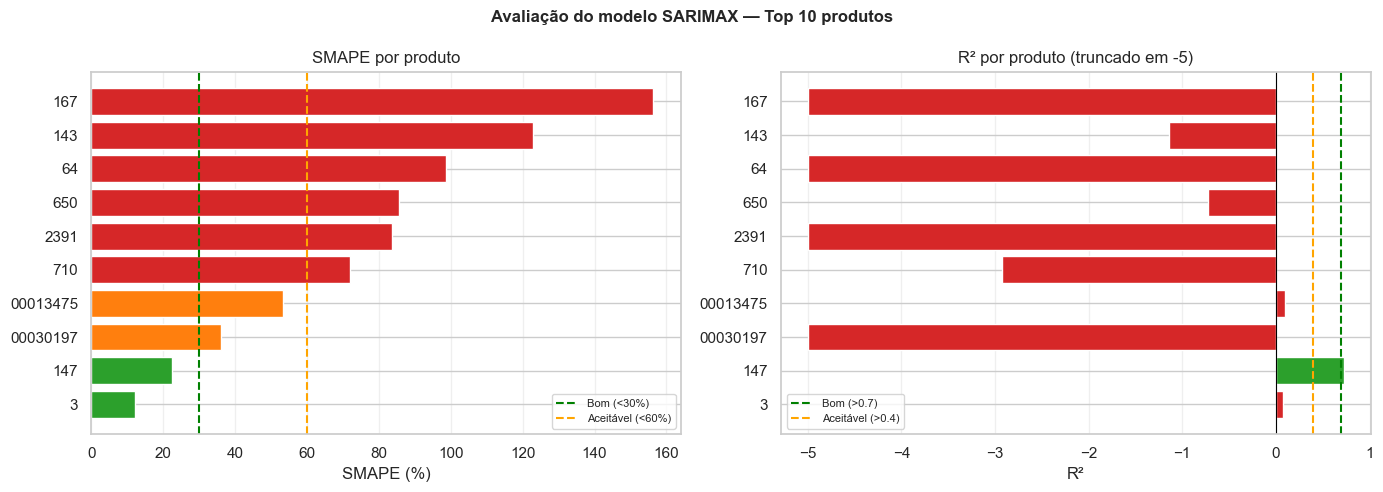

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

summary_sorted = summary.sort_values('SMAPE_%')

colors_smape = ['#2ca02c' if v < 30 else '#ff7f0e' if v < 60 else '#d62728'
                for v in summary_sorted['SMAPE_%']]
axes[0].barh(summary_sorted['produto_cod'].astype(str), summary_sorted['SMAPE_%'],
             color=colors_smape, edgecolor='white')
axes[0].axvline(30, color='green', linestyle='--', label='Bom (<30%)')
axes[0].axvline(60, color='orange', linestyle='--', label='Aceitável (<60%)')
axes[0].set_xlabel('SMAPE (%)')
axes[0].set_title('SMAPE por produto')
axes[0].legend(fontsize=8)
axes[0].grid(True, axis='x', alpha=0.3)

colors_r2 = ['#2ca02c' if v > 0.7 else '#ff7f0e' if v > 0.4 else '#d62728'
             for v in summary_sorted['R2']]
axes[1].barh(summary_sorted['produto_cod'].astype(str), summary_sorted['R2'].clip(lower=-5),
             color=colors_r2, edgecolor='white')
axes[1].axvline(0.7, color='green', linestyle='--', label='Bom (>0.7)')
axes[1].axvline(0.4, color='orange', linestyle='--', label='Aceitável (>0.4)')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_xlabel('R²')
axes[1].set_title('R² por produto (truncado em -5)')
axes[1].legend(fontsize=8)
axes[1].grid(True, axis='x', alpha=0.3)

plt.suptitle('Avaliação do modelo SARIMAX — Top 10 produtos', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'metricas_comparativas.png', dpi=150, bbox_inches='tight')
plt.show()

KeyError: ('MAPE_%', 'SMAPE_%')

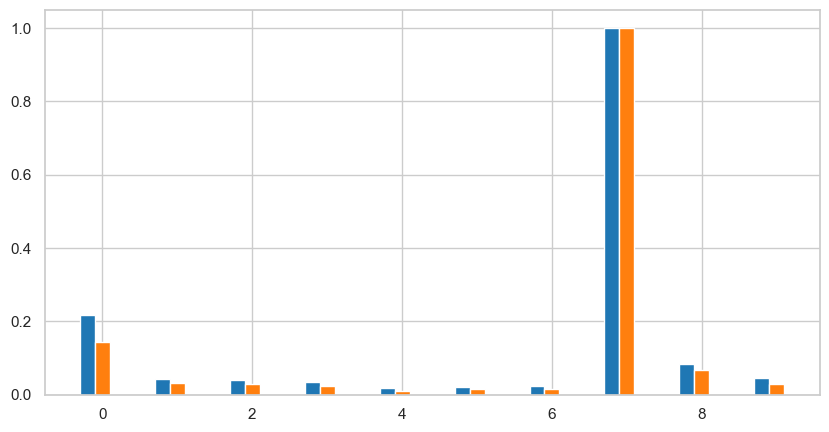

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

x = range(len(summary))
width = 0.2
prods = summary['produto_cod'].astype(str).tolist()

ax.bar([i - width for i in x], summary['MAE'] / summary['MAE'].max(), width, label='MAE (norm.)', color='#1f77b4')
ax.bar([i for i in x], summary['RMSE'] / summary['RMSE'].max(), width, label='RMSE (norm.)', color='#ff7f0e')
ax.bar([i + width for i in x], summary['SMAPE_%'] / 100, width, label='SMAPE/100', color='#d62728')
ax.bar([i + 2 * width for i in x], summary['R2'].clip(lower=0), width, label='R²', color='#2ca02c')

ax.set_xticks([i + width / 2 for i in x])
ax.set_xticklabels(prods, rotation=45, ha='right')
ax.set_ylabel('Valor (normalizado)')
ax.set_title('Comparação de métricas entre produtos (normalizado)')
ax.legend()
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(PLOTS_DIR / 'metricas_barras_agrupadas.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Análise individual — produto mais vendido

In [ ]:
df_loaded = load_data(DATA_PATH)

pipe_ref = run_product_pipeline(
    df_loaded,
    produto_cod=top_products[0],
    test_months=TEST_MONTHS,
    future_months=3,
    verbose=True,
)

In [ ]:
print(pipe_ref['model_result'].summary())

In [ ]:
comp = pd.DataFrame({'Real': pipe_ref['ts_test'], 'Previsto': pipe_ref['test_pred']})
comp['Erro_abs'] = (comp['Real'] - comp['Previsto']).abs()
comp['Erro_%'] = (comp['Erro_abs'] / (comp['Real'] + 1e-9) * 100).round(2)
print('Previsão vs Real (conjunto de teste):')
display(comp.round(2))

print('\nPrevisão futura (próximos 3 meses):')
display(pipe_ref['future_pred'].rename('Qtd_prevista').round(0).astype(int))

## 9. Conclusão

Arquivos gerados:
- `results/plots/` — gráficos de série, resíduos, correlações e métricas
- `results/metrics/metricas_sarimax.csv` — tabela consolidada

### Interpretação das métricas
| Métrica | Bom | Aceitável | Ruim |
|---------|-----|-----------|------|
| MAPE %  | < 20% | 20–35% | > 35% |
| R²      | > 0.70 | 0.40–0.70 | < 0.40 |